In [1]:
import matplotlib.pyplot as plt
import random
import matplotlib.patches as mpatches

# square lattice 

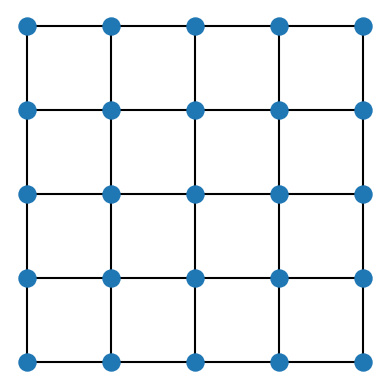

In [2]:
N = 5
X, Y = [], []
for i in range(N):
    for j in range(N):
        if i + 1 < N:
            plt.plot([i, i+1], [j, j], '-', c='black')
        if j + 1 < N:
            plt.plot([i, i], [j, j+1], '-', c='black')
for i in range(N):
    for j in range(N):
        X.append(i)
        Y.append(j)

plt.scatter(X, Y, s=150, marker='o', zorder=2)


ax = plt.gca()
ax.set_aspect('equal')
ax.axis('off')

plt.show()


# chain graph

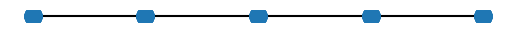

In [3]:
N = 5
X, Y = [], []
for i in range(N):
    if i + 1 < N:
        plt.plot([i, i+1], [0, 0], '-', c='black')
for i in range(N):
    for j in range(N):
        X.append(i)
        Y.append(0)

plt.scatter(X, Y, s=150, marker='o', zorder=2)


ax = plt.gca()
ax.set_aspect('equal')
ax.axis('off')

plt.show()


# complete graph

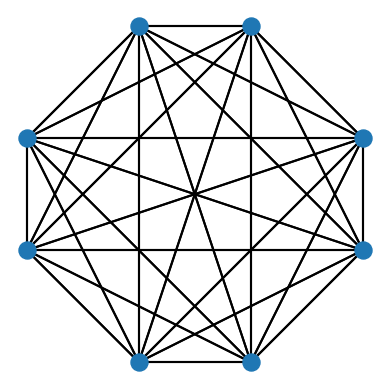

In [4]:
X = [0,0,1,1,2,2,3,3]
Y = [1,2,0,3,0,3,1,2]


for i in range(len(X)):
    point = (X[i], Y[i])
    for j in range(len(Y)):
        if i != j:
            point2 = (X[j], Y[j])
            plt.plot([point[0], point2[0]], [point[1], point2[1]], '-', c='black')


plt.scatter(X, Y, s=150, marker='o', zorder=2)


ax = plt.gca()
ax.set_aspect('equal')
ax.axis('off')

plt.show()


# weighted graph

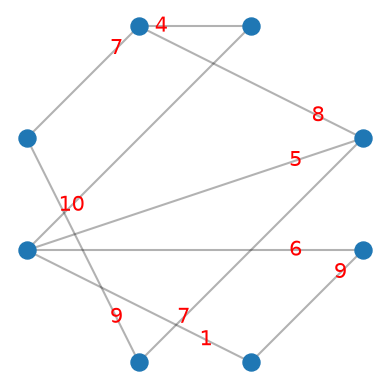

In [5]:
X = [0,0,1,1,2,2,3,3]
Y = [1,2,0,3,0,3,1,2]

random.seed(6)


done_edges = []

for i in range(len(X)):
    point = (X[i], Y[i])
    for j in range(len(Y)):
        if i != j:
            edge = tuple(sorted((i, j)))
            if edge not in done_edges and random.random() < 0.2:
                point2 = (X[j], Y[j])
                plt.plot([point[0], point2[0]], [point[1], point2[1]], '-', c='black', alpha=0.3)
                x_text = point[0] + (point2[0] - point[0]) / 5
                y_text = point[1] + (point2[1] - point[1]) / 5
                plt.text(x_text, y_text, str(random.randint(1, 10)), fontsize=15, ha='center', va='center',zorder=3, color='red')
                done_edges.append(edge)

plt.scatter(X, Y, s=150, marker='o', zorder=2)

ax = plt.gca()
ax.set_aspect('equal')
ax.axis('off')

plt.show()


# directed graph

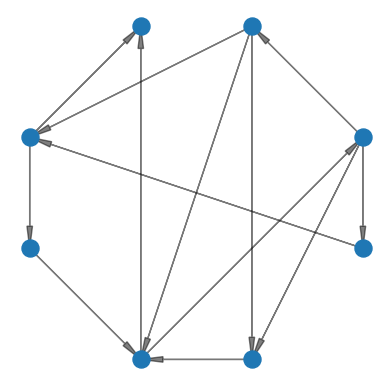

In [6]:
X = [0,0,1,1,2,2,3,3]
Y = [1,2,0,3,0,3,1,2]

random.seed(990)

done_edges = []

for i in range(len(X)):
    point = (X[i], Y[i])
    for j in range(len(Y)):
        if i != j:
            edge = tuple(sorted((i, j)))
            if edge not in done_edges and random.random() < 0.2:
                point2 = (X[j], Y[j])
                plt.arrow(point[0], point[1], point2[0] - point[0], point2[1] - point[1],
                          length_includes_head=True, head_width=0.05, head_length=0.2, 
                          fc='black', ec='black', alpha=0.5, lw=1, zorder=1)
                
                done_edges.append(edge)

plt.scatter(X, Y, s=150, marker='o', zorder=2)

ax = plt.gca()
ax.set_aspect('equal')
ax.axis('off')

plt.show()



# directed graph with in/out vertex degrees

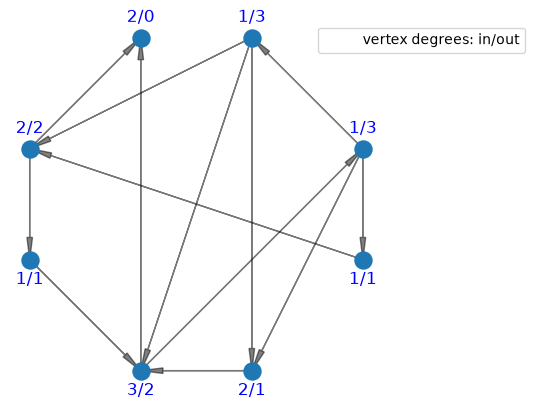

In [7]:
X = [0,0,1,1,2,2,3,3]
Y = [1,2,0,3,0,3,1,2]

random.seed(990)

done_edges = []
in_degrees = [0 for _ in range(len(X))]
out_degrees = [0 for _ in range(len(X))]

for i in range(len(X)):
    point = (X[i], Y[i])
    for j in range(len(Y)):
        if i != j:
            edge = (i,j)  # edge from i to j
            edge_undirected = tuple(sorted((i, j)))
            if edge_undirected not in done_edges and random.random() < 0.2:
                point2 = (X[j], Y[j])
                plt.arrow(point[0], point[1], point2[0] - point[0], point2[1] - point[1],
                          length_includes_head=True, head_width=0.05, head_length=0.2, 
                          fc='black', ec='black', alpha=0.5, lw=1, zorder=1)
                # out for i, in for j
                out_degrees[i] += 1
                in_degrees[j] += 1
                done_edges.append(edge_undirected)

plt.scatter(X, Y, s=150, marker='o', zorder=2)

for idx, (x, y) in enumerate(zip(X, Y)):
    if y <2: 
        plt.text(x, y-0.18, f"{in_degrees[idx]}/{out_degrees[idx]}", fontsize=12, ha='center', va='center', color='blue', zorder=3)
    else:
        plt.text(x, y+0.18, f"{in_degrees[idx]}/{out_degrees[idx]}", fontsize=12, ha='center', va='center', color='blue', zorder=3)

ax = plt.gca()
ax.set_aspect('equal')
ax.axis('off')

legend_patch = mpatches.Patch(color='none', label='vertex degrees: in/out')
plt.legend(handles=[legend_patch], loc='upper right', bbox_to_anchor=(1.4, 1))

plt.show()